In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [34]:
df=pd.read_csv("mall_customers.csv")
print(df.head())
print(df.info())
print(df.isnull().sum())

   customer_id  gender  age  annual_income  spending_score
0            1    Male   19             15              39
1            2    Male   21             15              81
2            3  Female   20             16               6
3            4  Female   23             16              77
4            5  Female   31             17              40
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customer_id     200 non-null    int64 
 1   gender          200 non-null    object
 2   age             200 non-null    int64 
 3   annual_income   200 non-null    int64 
 4   spending_score  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None
customer_id       0
gender            0
age               0
annual_income     0
spending_score    0
dtype: int64


In [35]:
from sklearn.preprocessing import StandardScaler
X=df[['annual_income',
      'spending_score']]
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)

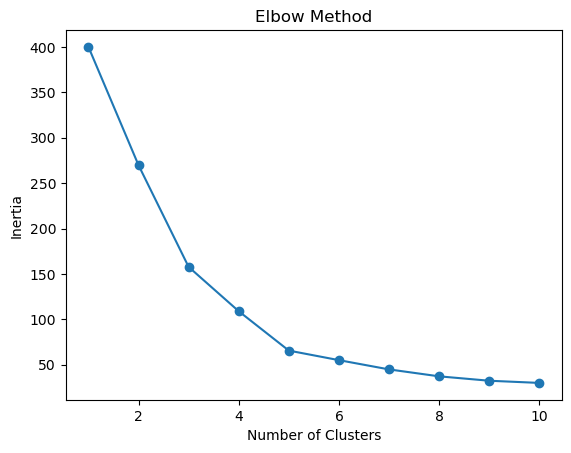

In [36]:

from sklearn.cluster import KMeans
inertias=[]
for k in range(1,11):
    model=KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    inertias.append(model.inertia_)
plt.plot(range(1,11),inertias,marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [37]:
k=5
kmeans=KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)
kmeans_labels=kmeans.fit_predict(X_scaled)

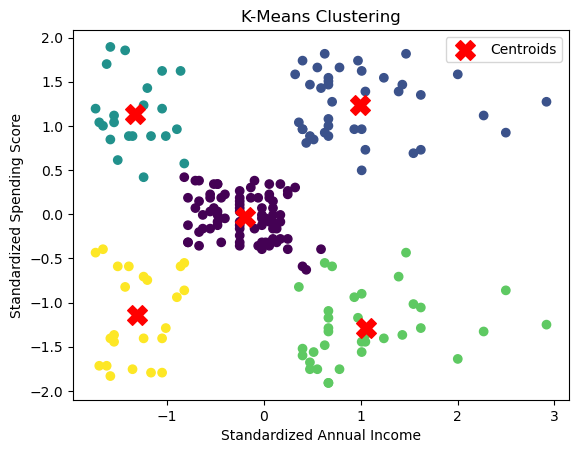

In [38]:
plt.scatter(
    X_scaled[:,0],
    X_scaled[:,1],
    c=kmeans_labels,
    cmap='viridis'
)
plt.scatter(
    kmeans.cluster_centers_[:,0],
    kmeans.cluster_centers_[:,1],
    c='red',
    marker='X',
    s=200,
    label='Centroids'
)
plt.xlabel("Standardized Annual Income")
plt.ylabel("Standardized Spending Score")
plt.title("K-Means Clustering")
plt.legend()
plt.show()

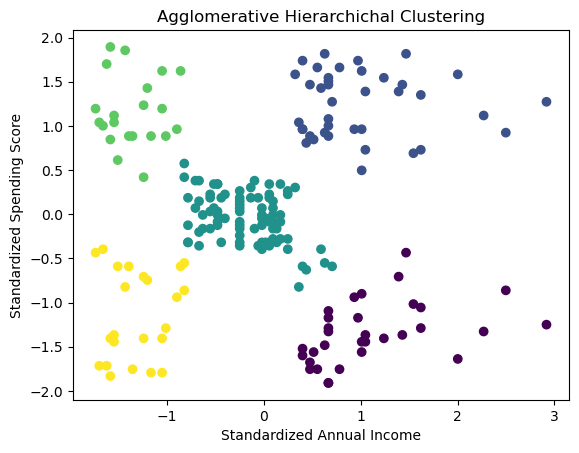

In [39]:
from sklearn.cluster import AgglomerativeClustering
hierarchichal=AgglomerativeClustering(
    n_clusters=k,
    linkage='ward'
)
hierarchichal_labels=(
    hierarchichal.fit_predict(X_scaled)
)
plt.scatter(
    X_scaled[:,0],
    X_scaled[:,1],
    c=hierarchichal_labels,
    cmap='viridis'
)
plt.xlabel("Standardized Annual Income")
plt.ylabel("Standardized Spending Score")
plt.title("Agglomerative Hierarchichal Clustering")
plt.show()

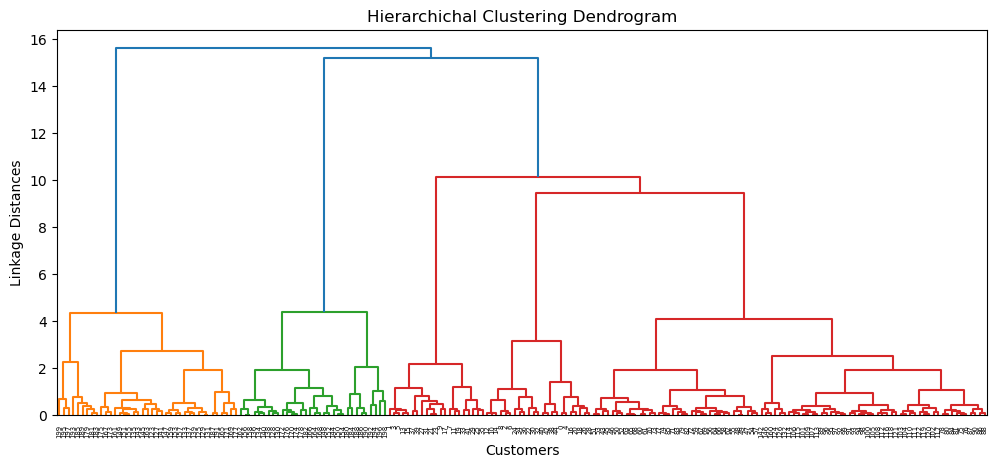

In [42]:
from scipy.cluster.hierarchy import(
linkage,dendrogram
)
linked=linkage(X_scaled,method='ward')
plt.figure(figsize=(12,5))
dendrogram(linked)
plt.title("Hierarchichal Clustering Dendrogram")
plt.xlabel("Customers")
plt.ylabel("Linkage Distances")
plt.show()

In [44]:
from sklearn.metrics import silhouette_score
import numpy as np
kmeans_sil=silhouette_score(
    X_scaled,kmeans_labels
)
hierarchichal_sil=silhouette_score(
    X_scaled,hierarchichal_labels
)

In [ ]:
def calcul